# Phase 2: choose the subset

Goal: pick about **2,000 photos per country** from Japan, India and Czech, by code, with a bias towards the classes that have the fewest photos. The bias is worked out from the counts below, not guessed.

In [1]:
import sys
import xml.etree.ElementTree as ET
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

sys.path.insert(0, str(Path.cwd().parents[1]))
from ml import config

PER_COUNTRY = 2000
MERGE = {"D00": "D00", "D01": "D00", "D10": "D10", "D11": "D10", "D20": "D20", "D40": "D40"}  # D01/D11 are joint cracks
CLASSES = ["D00", "D10", "D20", "D40", "clean"]
COLORS = ["#3b82f6", "#a855f7", "#f59e0b", "#ef4444", "#9ca3af"]

NAMES = {"D00": "D00 · Longitudinal crack (along the road)", "D10": "D10 · Transverse crack (across the road)",
         "D20": "D20 · Alligator crack (web of cracks)", "D40": "D40 · Pothole",
         "clean": "clean · none of our 4 classes in the photo"}
LEGEND = [plt.Rectangle((0, 0), 1, 1, color=col, label=NAMES[k]) for k, col in zip(CLASSES, COLORS)]

## 1. One row per photo: which of our classes does it contain?

In [2]:
rows = []
for country in config.COUNTRIES:
    for path in (config.RAW / country / "train" / "annotations" / "xmls").glob("*.xml"):
        found = [o.find("name").text for o in ET.parse(path).getroot().findall("object")]
        ours = {MERGE[c] for c in found if c in MERGE}
        rows.append({"image_id": path.stem, "country": country, **{k: k in ours for k in CLASSES[:4]}, "clean": not ours})

photos = pd.DataFrame(rows)
per_country = photos.groupby("country")[CLASSES].sum().loc[config.COUNTRIES]
per_country["total photos"] = photos.groupby("country").size()
per_country

,D00,D10,D20,D40,clean,total photos
country,,,,,,
Japan,2797,2240,4714,1390,2606,10506
India,1217,95,1758,1530,4388,7706
Czech,764,300,129,154,1757,2829


## 2. Chart: photos per class, per country, and combined

A photo counts once for every class it contains, so a photo with a crack and a pothole is in both bars.

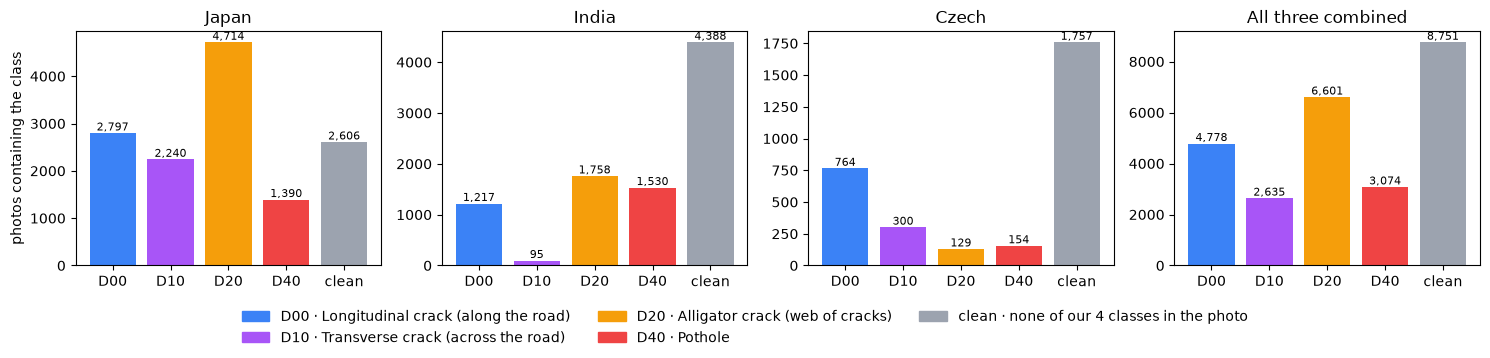

In [3]:
combined = per_country[CLASSES].sum()

fig, axes = plt.subplots(1, 4, figsize=(15, 3.6), sharey=False)
for ax, c in zip(axes, config.COUNTRIES):
    ax.bar(CLASSES, per_country.loc[c, CLASSES], color=COLORS)
    ax.set_title(c)
    for i, v in enumerate(per_country.loc[c, CLASSES]):
        ax.text(i, v, f"{v:,}", ha="center", va="bottom", fontsize=8)
axes[3].bar(CLASSES, combined, color=COLORS)
axes[3].set_title("All three combined")
for i, v in enumerate(combined):
    axes[3].text(i, v, f"{v:,}", ha="center", va="bottom", fontsize=8)
axes[0].set_ylabel("photos containing the class")
fig.legend(handles=LEGEND, loc="lower center", ncol=3, frameon=False)
plt.tight_layout(rect=(0, 0.14, 1, 1))
plt.show()

## 3. Work out the weights from the combined counts

Idea: the fewer photos a class has, the more likely we should be to pick a photo that contains it. So the weight is the **inverse of the combined count**, scaled so the most common class (clean road) has weight 1:

`weight = (photos of the most common class) / (photos of this class)`

A photo that contains several classes takes the weight of its **rarest** one.

In [4]:
weights = (combined.max() / combined).round(2)
pd.DataFrame({"photos": combined, "weight": weights}).T

,D00,D10,D20,D40,clean
photos,4778.00,2635.00,6601.00,3074.00,8751.0
weight,1.83,3.32,1.33,2.85,1.0


## 4. Pick the photos (seed 42, weighted random draw per country)

In [5]:
rng = np.random.default_rng(config.SEED)


def photo_weight(row):
    return max(weights[k] for k in CLASSES if row[k])


photos["weight"] = photos.apply(photo_weight, axis=1)
subset = pd.concat(
    g.iloc[rng.choice(len(g), size=PER_COUNTRY, replace=False, p=g["weight"] / g["weight"].sum())]
    for _, g in photos.groupby("country")
)
print(len(subset), "photos picked")
subset.groupby("country").size()

6000 photos picked


country
Czech    2000
India    2000
Japan    2000
dtype: int64

## 5. Did it work? Share of photos containing each class: before vs after

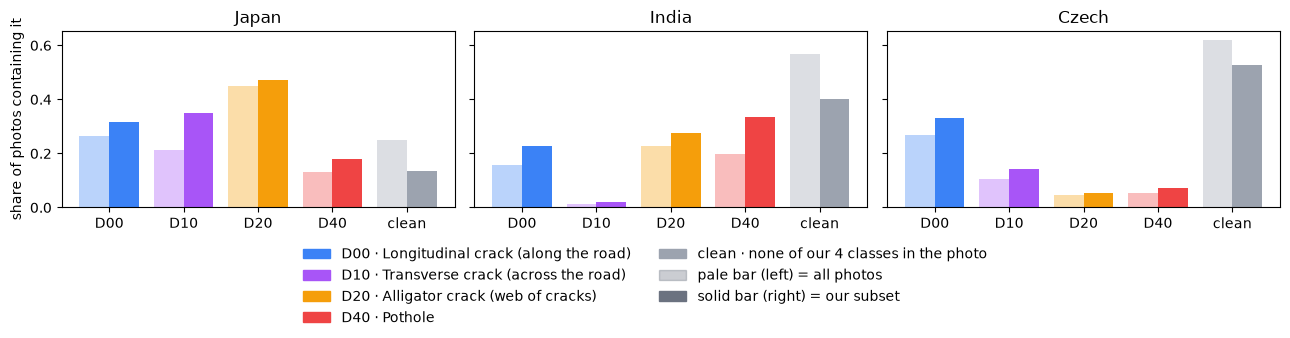

In [6]:
cols = CLASSES
before = photos.groupby("country")[cols].mean().loc[config.COUNTRIES]
after = subset.groupby("country")[cols].mean().loc[config.COUNTRIES]

fig, axes = plt.subplots(1, 3, figsize=(13, 3.4), sharey=True)
for ax, c in zip(axes, config.COUNTRIES):
    x = np.arange(len(cols))
    ax.bar(x - 0.2, before.loc[c], 0.4, color=COLORS, alpha=0.35)
    ax.bar(x + 0.2, after.loc[c], 0.4, color=COLORS)
    ax.set_xticks(x, cols)
    ax.set_title(c)
axes[0].set_ylabel("share of photos containing it")
fig.legend(handles=LEGEND + [plt.Rectangle((0, 0), 1, 1, color="#6b7280", alpha=0.35, label="pale bar (left) = all photos"), plt.Rectangle((0, 0), 1, 1, color="#6b7280", label="solid bar (right) = our subset")], loc="lower center", ncol=2, frameon=False)
plt.tight_layout(rect=(0, 0.26, 1, 1))
plt.show()

## 6. Box counts in the subset (the guide wants at least about 1,500 per class)

In [7]:
box_rows = []
for r in subset.itertuples():
    path = config.RAW / r.country / "train" / "annotations" / "xmls" / f"{r.image_id}.xml"
    for o in ET.parse(path).getroot().findall("object"):
        if o.find("name").text in MERGE:
            box_rows.append({"country": r.country, "cls": MERGE[o.find("name").text]})

counts = pd.DataFrame(box_rows).value_counts(["country", "cls"]).unstack(fill_value=0)[CLASSES[:4]].loc[config.COUNTRIES]
counts.loc["TOTAL"] = counts.sum()
counts

cls,D00,D10,D20,D40
country,,,,
Japan,929,1216,1212,607
India,664,48,631,1393
Czech,859,381,130,189
TOTAL,2452,1645,1973,2189


In [8]:
config.PROCESSED.mkdir(parents=True, exist_ok=True)
subset[["image_id", "country"]].sort_values("image_id").to_csv(config.PROCESSED / "subset_images.csv", index=False)
print("saved", config.PROCESSED / "subset_images.csv")

saved /Users/user/Documents/Y4/ML/road-damage-classifier/backend/data/processed/subset_images.csv


## Decision

**Subset: Japan + India + Czech, 2,000 photos each = 6,000 photos (about 240,000 squares).**

**Why these countries:** they are all shot from a driver's view with the same damage codes, and together they have all four classes. Skipped: Norway (huge, wide photos), the US (not needed) and China_Drone (shot from above).

**Why 2,000 per country:** all 21,000 photos would give about 840,000 squares, too slow for an SVM on a laptop.

**What the chart shows (photos containing each class, all three countries combined):**

| | clean | D20 | D00 | D40 | D10 |
|---|---|---|---|---|---|
| Photos | 8,751 | 6,601 | 4,778 | 3,074 | **2,635** |

- Alligator cracks (D20) are the most common damage, and **transverse cracks (D10) are the rarest**.
- The countries differ a lot: Japan has most of the damage, India is mostly clean road, and Czech has very few D20 and D40.
- India has only 95 photos with a D10, and Czech only 300.

**Weights, worked out from those counts:** `weight = 8,751 / photos of the class`, so the rarer the class, the more likely a photo containing it is picked.

| Class | clean | D20 | D00 | D40 | D10 |
|---|---|---|---|---|---|
| Weight | 1 | 1.33 | 1.83 | 2.85 | **3.32** |

A photo with several classes takes the weight of its rarest one. D10 gets the highest weight because it has the fewest photos, which is the bias we wanted, and it comes from the data.

**Result:**

| Boxes in the subset | D00 | D10 | D20 | D40 |
|---|---|---|---|---|
| Total | 2,452 | 1,645 | 1,973 | 2,189 |

All four are above the guide's 1,500-box minimum.

**Known limits:**
- D10 is still the smallest class (1,645 boxes), and Japan supplies 74% of them. India keeps only 48 D10 boxes (a weighted draw doesn't keep every one of the 95 photos), so in Phase 5 check the model still works on transverse cracks from India and Czech.
- If the model is weak on D10 later, the fix is to raise its weight or add more Japan D10 photos, then re-run this notebook.

The photo list is saved as `data/processed/subset_images.csv`; Phase 3 reads from it.